## Installing dependencies


In [1]:
pip install numpy pandas scipy scikit-learn statsmodels matplotlib seaborn jupyter


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: pip3.12 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_poisson_deviance
import statsmodels.api as sm
import statsmodels.formula.api as smf

SEED = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

## Loading the Dataset

In [2]:
df = fetch_openml(data_id=41214, as_frame=True, parser="pandas").frame
df["IDpol"] = df["IDpol"].astype(int)
df = df.set_index("IDpol")
print(df.shape)
df.head()

(678013, 11)


,ClaimNb,Exposure,Area,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Density,Region
IDpol,,,,,,,,,,,
1,1,0.10,D,5,0,55,50,B12,'Regular',1217,R82
3,1,0.77,D,5,0,55,50,B12,'Regular',1217,R82
5,1,0.75,B,6,2,52,50,B12,'Diesel',54,R22
10,1,0.09,B,7,0,46,50,B12,'Diesel',76,R72
11,1,0.84,B,7,0,46,50,B12,'Diesel',76,R72


## Exploratory Data Analysis

In [3]:
df.info()
print(df.describe().T)
print("Missing values:\n", df.isna().sum())
print("Total claims:", df["ClaimNb"].sum(), "| Total exposure (years):", round(df["Exposure"].sum()))
print("Overall claim frequency:", round(df["ClaimNb"].sum() / df["Exposure"].sum(), 4))

<class 'pandas.core.frame.DataFrame'>
Index: 678013 entries, 1 to 6114330
Data columns (total 11 columns):
 #   Column      Non-Null Count   Dtype   
---  ------      --------------   -----   
 0   ClaimNb     678013 non-null  int64   
 1   Exposure    678013 non-null  float64 
 2   Area        678013 non-null  category
 3   VehPower    678013 non-null  int64   
 4   VehAge      678013 non-null  int64   
 5   DrivAge     678013 non-null  int64   
 6   BonusMalus  678013 non-null  int64   
 7   VehBrand    678013 non-null  category
 8   VehGas      678013 non-null  object  
 9   Density     678013 non-null  int64   
 10  Region      678013 non-null  category
dtypes: category(3), float64(1), int64(6), object(1)
memory usage: 48.5+ MB
               count         mean          std        min    25%     50%  \
ClaimNb     678013.0     0.053247     0.240117   0.000000   0.00    0.00   
Exposure    678013.0     0.528750     0.364442   0.002732   0.18    0.49   
VehPower    678013.0     6.454

### Duplicate and Unusual values

In [4]:
print("Duplicate rows:", df.duplicated().sum())
print("Exposure > 1:", (df["Exposure"] > 1).sum(), "| Exposure min:", df["Exposure"].min())
print(df["ClaimNb"].value_counts().sort_index())
print(df[["VehAge", "DrivAge", "BonusMalus", "Density"]].describe().T[["min", "50%", "max"]])

Duplicate rows: 28688
Exposure > 1: 1224 | Exposure min: 0.0027322404371584
ClaimNb
0     643953
1      32178
2       1784
3         82
4          7
5          2
6          1
8          1
9          1
11         3
16         1
Name: count, dtype: int64
             min    50%      max
VehAge       0.0    6.0    100.0
DrivAge     18.0   44.0    100.0
BonusMalus  50.0   50.0    230.0
Density      1.0  393.0  27000.0


### Cleaning the data

In [5]:
df_clean = df.copy()
df_clean["ClaimNb"]    = df_clean["ClaimNb"].clip(upper=4)      # cap rare extreme claim counts
df_clean["Exposure"]   = df_clean["Exposure"].clip(upper=1)     # a policy can't exceed a year
df_clean["VehAge"]     = df_clean["VehAge"].clip(upper=20)
df_clean["DrivAge"]    = df_clean["DrivAge"].clip(upper=90)
df_clean["BonusMalus"] = df_clean["BonusMalus"].clip(upper=150)
df_clean["LogDensity"] = np.log(df_clean["Density"])            # density is very skewed, so use a log scale
df_clean["Frequency"]  = df_clean["ClaimNb"] / df_clean["Exposure"]

# group ages into bands, which makes the GLM easier to read
df_clean["DrivAgeBand"] = pd.cut(df_clean["DrivAge"], [17, 21, 25, 30, 40, 50, 60, 70, 91], right=False)
df_clean["VehAgeBand"]  = pd.cut(df_clean["VehAge"], [0, 1, 5, 10, 21], right=False)

# make the category columns proper categories
for c in ["Area", "VehBrand", "VehGas", "Region"]:
    df_clean[c] = df_clean[c].astype("category")

In [6]:
print(df_clean[["ClaimNb", "Exposure", "VehAge", "DrivAge", "BonusMalus"]].max())
print("Rows:", len(df_clean), "| Claim frequency after cleaning:",
      round(df_clean["ClaimNb"].sum() / df_clean["Exposure"].sum(), 4))

ClaimNb         4.0
Exposure        1.0
VehAge         20.0
DrivAge        90.0
BonusMalus    150.0
dtype: float64
Rows: 678013 | Claim frequency after cleaning: 0.1006


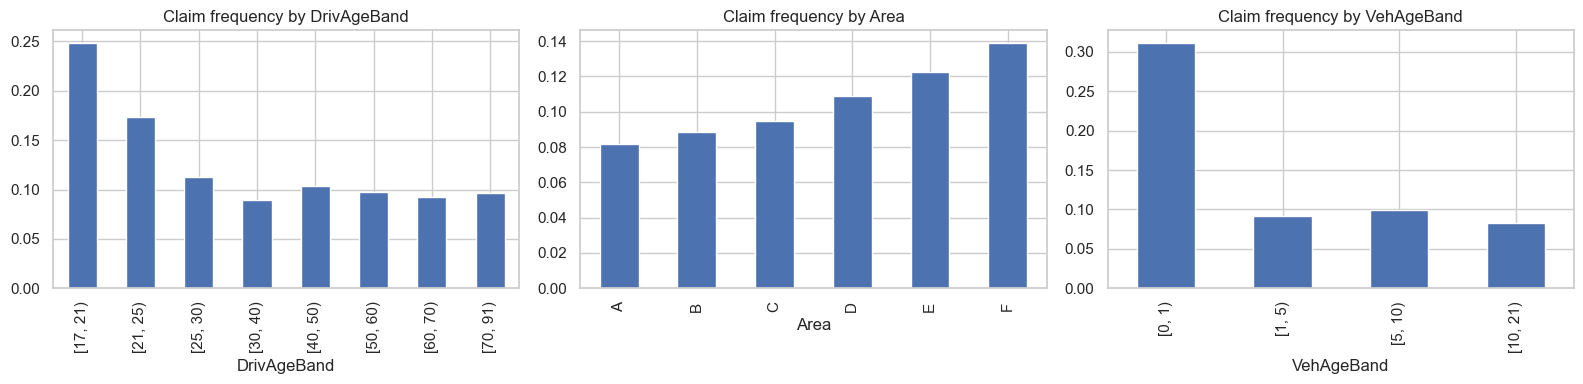

In [7]:
def freq_by(col):
    g = df_clean.groupby(col, observed=True).agg(claims=("ClaimNb", "sum"), exposure=("Exposure", "sum"))
    g["frequency"] = g["claims"] / g["exposure"]
    return g

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["DrivAgeBand", "Area", "VehAgeBand"]):
    freq_by(col)["frequency"].plot(kind="bar", ax=ax, title=f"Claim frequency by {col}")
plt.tight_layout(); plt.show()

In [8]:
   for col in ["DrivAgeBand", "Area", "VehAgeBand"]:
       print(freq_by(col)[["exposure", "frequency"]].round(3), "\n")
   print("Overall:", round(df_clean["ClaimNb"].sum() / df_clean["Exposure"].sum(), 4))

              exposure  frequency
DrivAgeBand                      
[17, 21)      2584.543      0.249
[21, 25)      9904.348      0.174
[25, 30)     25775.651      0.112
[30, 40)     82320.268      0.089
[40, 50)     87645.366      0.103
[50, 60)     79880.858      0.097
[60, 70)     40077.472      0.093
[70, 91)     30171.599      0.096 

        exposure  frequency
Area                       
A      61956.828      0.082
B      43001.824      0.088
C     104402.524      0.095
D      77087.802      0.109
E      63785.694      0.122
F       8125.434      0.139 

              exposure  frequency
VehAgeBand                       
[0, 1)       16696.329      0.312
[1, 5)      112268.675      0.092
[5, 10)     100225.808      0.099
[10, 21)    129169.294      0.082 

Overall: 0.1006


### Observations
Drivers aged 18–20 have the highest claim frequency, about 0.249 claims per policy-year against an overall rate of 0.10, so young drivers are the riskiest group. Frequency rises gradually from Area A (rural) to Area F (city), from 0.082 to 0.139, a steady but modest increase. Vehicles aged 0–1 show a higher frequency than older vehicles (0.312 vs 0.082), though this band has less exposure, so I will check whether the GLM confirms the effect once the other factors are controlled for.

## Splitting the Dataset

In [9]:
train, test = train_test_split(df_clean, test_size=0.2, random_state=SEED)

## Fit the GLM

In [10]:
formula = ("ClaimNb ~ C(DrivAgeBand) + C(VehAgeBand) + C(Area) + C(VehGas) + C(VehBrand)"
           " + C(Region) + VehPower + BonusMalus + LogDensity")

glm = smf.glm(formula, data=train,
              family=sm.families.Poisson(),
              offset=np.log(train["Exposure"])).fit()
print(glm.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                ClaimNb   No. Observations:               542410
Model:                            GLM   Df Residuals:                   542359
Model Family:                 Poisson   Df Model:                           50
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:            -1.1269e+05
Date:                Thu, 08 Oct 2026   Deviance:                   1.7000e+05
Time:                        16:30:13   Pearson chi2:                 1.21e+06
No. Iterations:                     7   Pseudo R-squ. (CS):            0.01648
Covariance Type:            nonrobust                                         
                                                        coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------

## TEST GLM 

In [15]:
pred_glm = glm.predict(test, offset=np.log(test["Exposure"]))
glm_dev = mean_poisson_deviance(test["ClaimNb"], pred_glm)
print("GLM test deviance:", round(glm_dev, 4))

GLM test deviance: 0.3165


In [12]:
base_rate = train["ClaimNb"].sum() / train["Exposure"].sum()
pred_base = test["Exposure"] * base_rate
base_dev = mean_poisson_deviance(test["ClaimNb"], pred_base)
print("Baseline test deviance:", round(base_dev, 4))

Baseline test deviance: 0.3312


## Gradient Boosting Benchmark

In [13]:
features = ["DrivAge", "VehAge", "VehPower", "BonusMalus", "LogDensity",
            "Area", "VehBrand", "VehGas", "Region"]

gbm = HistGradientBoostingRegressor(
    loss="poisson",
    learning_rate=0.1,
    max_iter=300,
    max_leaf_nodes=16,
    min_samples_leaf=200,
    early_stopping=True,
    categorical_features="from_dtype",
    random_state=SEED,
)
gbm.fit(train[features],
        train["ClaimNb"] / train["Exposure"],       # target = frequency
        sample_weight=train["Exposure"])            # longer policies count for more

pred_gbm = gbm.predict(test[features]) * test["Exposure"]   # convert back to expected claims
gbm_dev = mean_poisson_deviance(test["ClaimNb"], pred_gbm)
print("GBM test deviance:", round(gbm_dev, 4))

GBM test deviance: 0.3055


In [16]:
results = pd.DataFrame({
    "Model": ["Baseline (average rate)", "Poisson GLM", "Gradient boosting"],
    "Test Poisson deviance": [base_dev, glm_dev, gbm_dev],
}).round(4)
results

,Model,Test Poisson deviance
0,Baseline (average rate),0.3312
1,Poisson GLM,0.3165
2,Gradient boosting,0.3055


### GLM Relativities for Tableau

In [17]:
import re

def label(factor, level):
    iv = re.match(r"Interval\((\d+), (\d+), closed='left'\)", level) or re.match(r"\[(\d+), (\d+)\)", level)
    if iv:
        return f"{iv.group(1)}-{int(iv.group(2)) - 1}"
    return level.strip("'")

conf = glm.conf_int()
rows = []
for name in glm.params.index.drop("Intercept"):
    m = re.match(r"C\((\w+)\)\[T\.(.*)\]", name)
    factor, level = (m.group(1), label(m.group(1), m.group(2))) if m else (name, "per unit increase")
    rows.append({"factor": factor, "level": level,
                 "relativity": np.exp(glm.params[name]),
                 "ci_low": np.exp(conf.loc[name, 0]),
                 "ci_high": np.exp(conf.loc[name, 1]),
                 "p_value": glm.pvalues[name]})

# add the baseline level of each categorical factor, fixed at 1.0
for f in ["DrivAgeBand", "VehAgeBand", "Area", "VehGas", "VehBrand", "Region"]:
    first = train[f].cat.categories[0]
    rows.append({"factor": f, "level": label(f, str(first)), "relativity": 1.0,
                 "ci_low": 1.0, "ci_high": 1.0, "p_value": np.nan})

relativities = pd.DataFrame(rows).sort_values(["factor", "level"]).round(3)
relativities.to_csv("glm_relativities.csv", index=False)
relativities.head(20)

,factor,level,relativity,ci_low,ci_high,p_value
52,Area,A,1.000,1.000,1.000,NaN
10,Area,B,1.026,0.970,1.085,0.366
11,Area,C,1.011,0.940,1.087,0.762
12,Area,D,1.044,0.935,1.165,0.446
13,Area,E,1.038,0.897,1.202,0.617
14,Area,F,0.977,0.798,1.195,0.819
48,BonusMalus,per unit increase,1.023,1.023,1.024,0.000
50,DrivAgeBand,17-20,1.000,1.000,1.000,NaN
0,DrivAgeBand,21-24,0.758,0.684,0.840,0.000
1,DrivAgeBand,25-29,0.641,0.581,0.707,0.000


## Relativity Chart for README

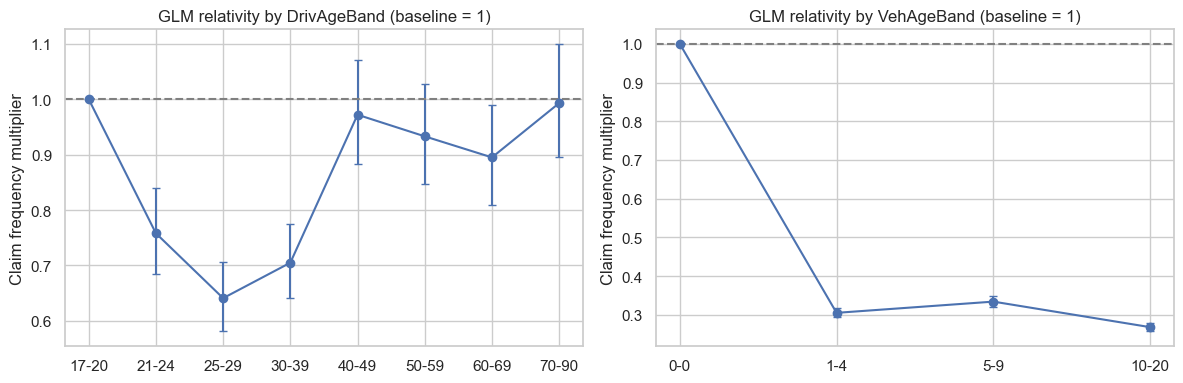

In [18]:
import os
os.makedirs("figures", exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, f in zip(axes, ["DrivAgeBand", "VehAgeBand"]):
    d = relativities[relativities["factor"] == f].copy()
    d["k"] = d["level"].str.extract(r"(\d+)")[0].astype(int)
    d = d.sort_values("k")
    ax.errorbar(d["level"], d["relativity"],
                yerr=[d["relativity"] - d["ci_low"], d["ci_high"] - d["relativity"]],
                fmt="o-", capsize=3)
    ax.axhline(1, ls="--", c="grey")
    ax.set_title(f"GLM relativity by {f} (baseline = 1)")
    ax.set_ylabel("Claim frequency multiplier")
plt.tight_layout()
plt.savefig("figures/glm_relativities.png", dpi=150)
plt.show()

## Which factors Boosted the GBM performance

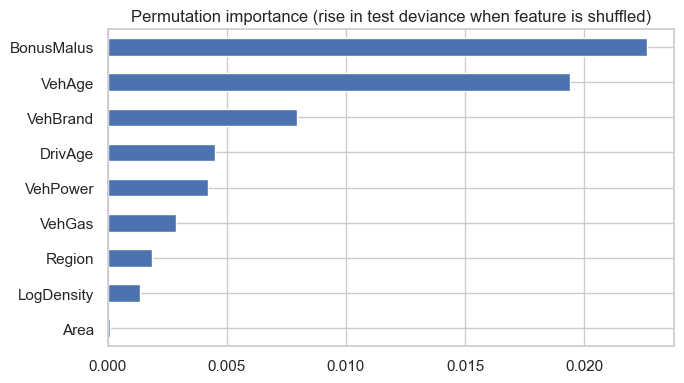

In [19]:
rng = np.random.default_rng(SEED)
sample = test.sample(50000, random_state=SEED)

def dev(X):
    return mean_poisson_deviance(sample["ClaimNb"], gbm.predict(X[features]) * sample["Exposure"])

base = dev(sample)
imp = {}
for f in features:
    scores = []
    for _ in range(3):
        X = sample.copy()
        X[f] = X[f].sample(frac=1, random_state=int(rng.integers(1_000_000_000))).values
        scores.append(dev(X) - base)
    imp[f] = np.mean(scores)

pd.Series(imp).sort_values().plot(kind="barh", figsize=(7, 4),
        title="Permutation importance (rise in test deviance when feature is shuffled)")
plt.tight_layout()
plt.savefig("figures/gbm_importance.png", dpi=150)
plt.show()

## Exporting files for Tableau

In [20]:
rel_t = relativities.copy()
rel_t["level"] = rel_t["level"].replace({"0-0": "0"})          # cleaner label for cars under 1 year
rel_t["sort_key"] = pd.to_numeric(rel_t["level"].str.extract(r"(\d+)")[0], errors="coerce")
rel_t["significance"] = np.where(rel_t["p_value"].isna(), "Baseline",
                         np.where(rel_t["p_value"] < 0.05, "Significant", "Not significant"))
rel_t.to_csv("glm_relativities_tableau.csv", index=False)

(pd.Series(imp, name="importance").rename_axis("feature").reset_index()
   .sort_values("importance").to_csv("gbm_importance.csv", index=False))
print(rel_t.shape, "files saved")

(56, 8) files saved
